# OWCM Library Use Case Tutorial

This tutorial demonstrates how to use the **Optical Wireless Channel Model (OWCM)** library. We will cover:

1.  **Basic Concepts**: Links, Environments, and Transmitters/Receivers.
2.  **Discovery**: How to find available models.
3.  **Manual Composition**: Building a channel from scratch.
4.  **"Cooking" New Models**: How to create and register your own custom models.
5.  **Defaults & Recipes (High-Level API)**: The easy way to use the library.
6.  **Advanced**: Multiplying your own gain with an existing model (Chaining).

## 1. Basic Concepts

All simulations revolve around a few core data structures:
*   `Tx`: Transmitter (position, power, wavelength, divergence).
*   `Rx`: Receiver (position, aperture, FOV, sensitivity).
*   `Link`: Connects a Tx and Rx, automatically calculating range.
*   `Environment`: Context for the simulation (e.g., water type, atmospheric conditions).

In [22]:
# Reload modules to pick up latest implementations
import importlib
import sys

# Remove cached modules
modules_to_reload = [m for m in sys.modules.keys() if 'owcm' in m]
for module in modules_to_reload:
    del sys.modules[module]

# Re-import
import owcm
import owcm.atmospheric
import owcm.atmospheric.models
from owcm.atmospheric.models import attenuation, turbulence, pointing
import owcm.space.models

print("Modules reloaded successfully!")

Modules reloaded successfully!


In [24]:
import numpy as np
from owcm.core.types import Tx, Rx, Link, Environment

# Create a default Transmitter (1550nm, 0dBm)
tx = Tx()
print("Default Tx:", tx)

# Create a Receiver 1km away on Z-axis
rx = Rx(position=np.array([0.0, 0.0, 1000.0]))
print("Rx Position:", rx.position)

# Create the Link
link = Link(tx=tx, rx=rx)
print(f"Link Range: {link.range_m} meters")

Default Tx: Tx(position=array([0., 0., 0.]), power_dbm=0.0, wavelength_nm=1550.0, divergence_angle_rad=0.0, aperture_diameter_m=0.05)
Rx Position: [   0.    0. 1000.]
Link Range: 1000.0 meters


## 2. Discovery: Finding Models

The library uses a **Registry** to manage models. You can see what's available without digging through source code.

In [23]:
from owcm.core import registry

# 1. List all registered environments
envs = registry.list_environments()
print("Available Environments:", envs)

# 2. List models for a specific environment (e.g., 'space')
# Note: Models might need to be imported once to appear in the registry if they aren't auto-loaded.
# The library handles most of this via 'recipes', but importing the subpackage helps.
import owcm.space.models

atm_models = registry.list_models("atmospheric")
print("\nAtmosphere Models:")
for category, names in atm_models.items():
    print(f"  {category}: {names}")

space_models = registry.list_models("space")
print("\nSpace Models:")
for category, names in space_models.items():
    print(f"  {category}: {names}")

Available Environments: ['atmospheric', 'indoor', 'space', 'underground', 'underwater']

Atmosphere Models:
  geometry: ['uniform_aperture', 'gaussian_collected_exact', 'gaussian_collected_approx']
  attenuation: ['beer_lambert', 'kim', 'kruse', 'al_naboulsi_convection', 'al_naboulsi_advection', 'ijaz', 'esmail']
  turbulence: ['lognormal', 'gamma_gamma', 'negative_exponential']
  pointing: ['rayleigh_gaussian', 'none', 'hoyt_gaussian', 'beckmann_gaussian']

Space Models:
  free_space: ['fspl']
  tx_gain: ['diffraction_limited']
  rx_gain: ['telescope']
  pointing: ['none', 'gaussian']
  atmospheric_entry: ['none', 'beer_lambert']
  link_budget: ['multiplicative_chain']
  deepspace: ['table_xiii']


In [19]:
import numpy as np
from owcm import Channel
from owcm.core import registry

# Common parameters for all links
distance = 1000         # metres
wavelength = 1550       # nm
tx_power_w = 0.5        # Watts

# Helper to run a specific channel with selected models
def run_channel(env_name, geometry=None, attenuation=None, turbulence=None,
                pointing=None, extra_params=None):
    builder = Channel.environment(env_name)
    if geometry:
        builder = builder.model("geometry", geometry)
    if attenuation:
        builder = builder.model("attenuation", attenuation)
    if turbulence:
        builder = builder.model("turbulence", turbulence)
    if pointing:
        builder = builder.model("pointing", pointing)

    # Build the channel (passing any required parameters)
    params = {
        "distance_m": distance,
        "wavelength_nm": wavelength,
        "pt_w": tx_power_w,
    }
    if extra_params:
        params.update(extra_params)

    channel = builder.build(**params)
    return channel.gain()

# ---- Atmospheric example ----
atm_models = registry.list_models("atmospheric")
print("Atmospheric models:", atm_models)

# Loop through each attenuation model and evaluate gain
for att_model in atm_models["attenuation"]:
    try:
        extra = {"visibility_km": 2.0}
        # Esmail requires regression coefficients k, a, b
        if att_model == "esmail":
            extra.update({"k": 0.38, "a": 0.007, "b": 1.2})  # Example coefficients
        
        gain = run_channel(
            env_name="atmospheric",
            geometry="uniform_aperture",
            attenuation=att_model,
            turbulence="lognormal",
            pointing="rayleigh_gaussian",
            extra_params=extra
        )
        print(f"Atmospheric attenuation '{att_model}' gain: {gain:.4e}")
    except (NotImplementedError, TypeError, ValueError) as e:
        print(f"Atmospheric attenuation '{att_model}' error: {str(e)[:80]}")

# Evaluate turbulence models
for turb_model in atm_models["turbulence"]:
    try:
        gain = run_channel(
            env_name="atmospheric",
            geometry="uniform_aperture",
            attenuation="kim",
            turbulence=turb_model,
            pointing="none",
            extra_params={"gg_alpha": 3.2, "gg_beta": 2.1, "sigma_R2": 0.1, "visibility_km": 2.0}
        )
        print(f"Atmospheric turbulence '{turb_model}' gain: {gain:.4e}")
    except (NotImplementedError, TypeError, ValueError) as e:
        print(f"Atmospheric turbulence '{turb_model}' error: {str(e)[:80]}")

# Evaluate pointing models
for point_model in atm_models["pointing"]:
    try:
        gain = run_channel(
            env_name="atmospheric",
            geometry="uniform_aperture",
            attenuation="kim",
            turbulence="lognormal",
            pointing=point_model,
            extra_params={"jitter_sigma_m": 0.01, "wz_eq_m": 0.1, "visibility_km": 2.0}
        )
        print(f"Atmospheric pointing '{point_model}' gain: {gain:.4e}")
    except (NotImplementedError, TypeError, ValueError) as e:
        print(f"Atmospheric pointing '{point_model}' error: {str(e)[:80]}")

Atmospheric models: {'geometry': ['uniform_aperture', 'gaussian_collected_exact', 'gaussian_collected_approx'], 'attenuation': ['beer_lambert', 'kim', 'kruse', 'al_naboulsi_convection', 'al_naboulsi_advection', 'ijaz', 'esmail'], 'turbulence': ['lognormal', 'gamma_gamma', 'negative_exponential'], 'pointing': ['rayleigh_gaussian', 'none', 'hoyt_gaussian', 'beckmann_gaussian']}
Atmospheric attenuation 'beer_lambert' gain: 8.7214e-03
Atmospheric attenuation 'kim' gain: 3.2515e-03
Atmospheric attenuation 'kruse' gain: 3.5073e-03
Atmospheric attenuation 'al_naboulsi_convection' gain: 1.1717e-03
Atmospheric attenuation 'al_naboulsi_advection' gain: 9.6725e-04
Atmospheric attenuation 'ijaz' gain: 1.5672e-03
Atmospheric attenuation 'esmail' gain: 8.3979e-03
Atmospheric turbulence 'lognormal' gain: 3.3816e-03
Atmospheric turbulence 'gamma_gamma' gain: 3.3816e-03
Atmospheric turbulence 'negative_exponential' gain: 3.3816e-03
Atmospheric pointing 'rayleigh_gaussian' gain: 3.2515e-03
Atmospheric p

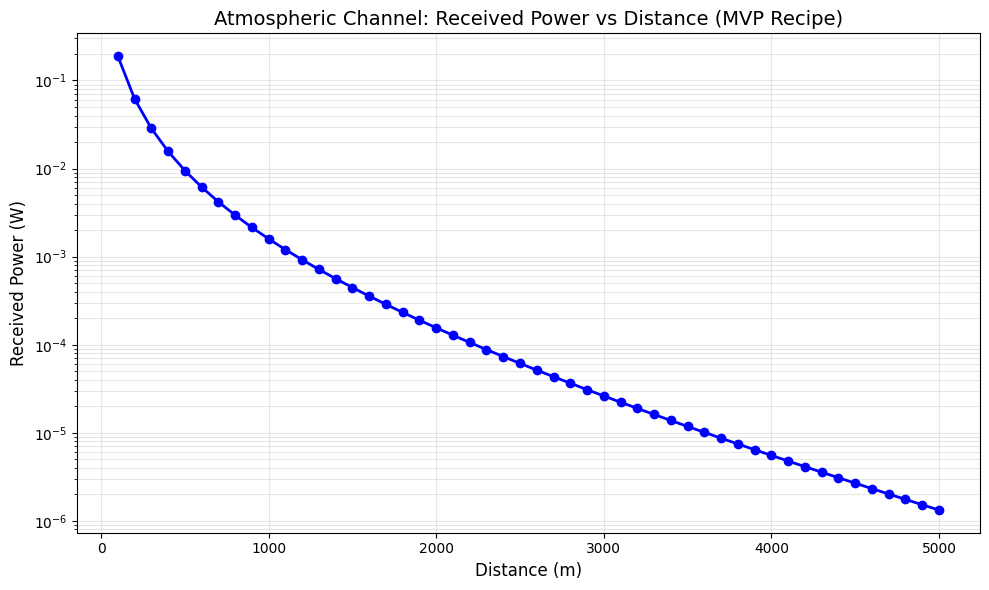

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from owcm import Channel

# Define distance range (in meters)
distances = np.linspace(100, 5000, 50)  # 100m to 5km
received_powers = []

# Build atmospheric channel and calculate received power for each distance
for distance in distances:
    ch_atm = Channel.environment("atmospheric").defaults("mvp").build(
        distance_m=distance,
        wavelength_nm=1550,
        pt_w=0.5,  # 0.5 W transmit power
        visibility_km=2.0,  # 2 km visibility
        theta_rad=1e-3,
        DT_m=0.05,
        DR_m=0.1,
        gg_alpha=3.2,
        gg_beta=2.1,
        jitter_sigma_m=0.01,
        wz_eq_m=0.08
    )
    pr = ch_atm.received_power()
    received_powers.append(pr)

# Plot results
plt.figure(figsize=(10, 6))
plt.semilogy(distances, received_powers, 'b-o', linewidth=2, markersize=6)
plt.xlabel('Distance (m)', fontsize=12)
plt.ylabel('Received Power (W)', fontsize=12)
plt.title('Atmospheric Channel: Received Power vs Distance (MVP Recipe)', fontsize=14)
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

Simulating 1 hour(s) at 100 Hz
Total samples: 360,000


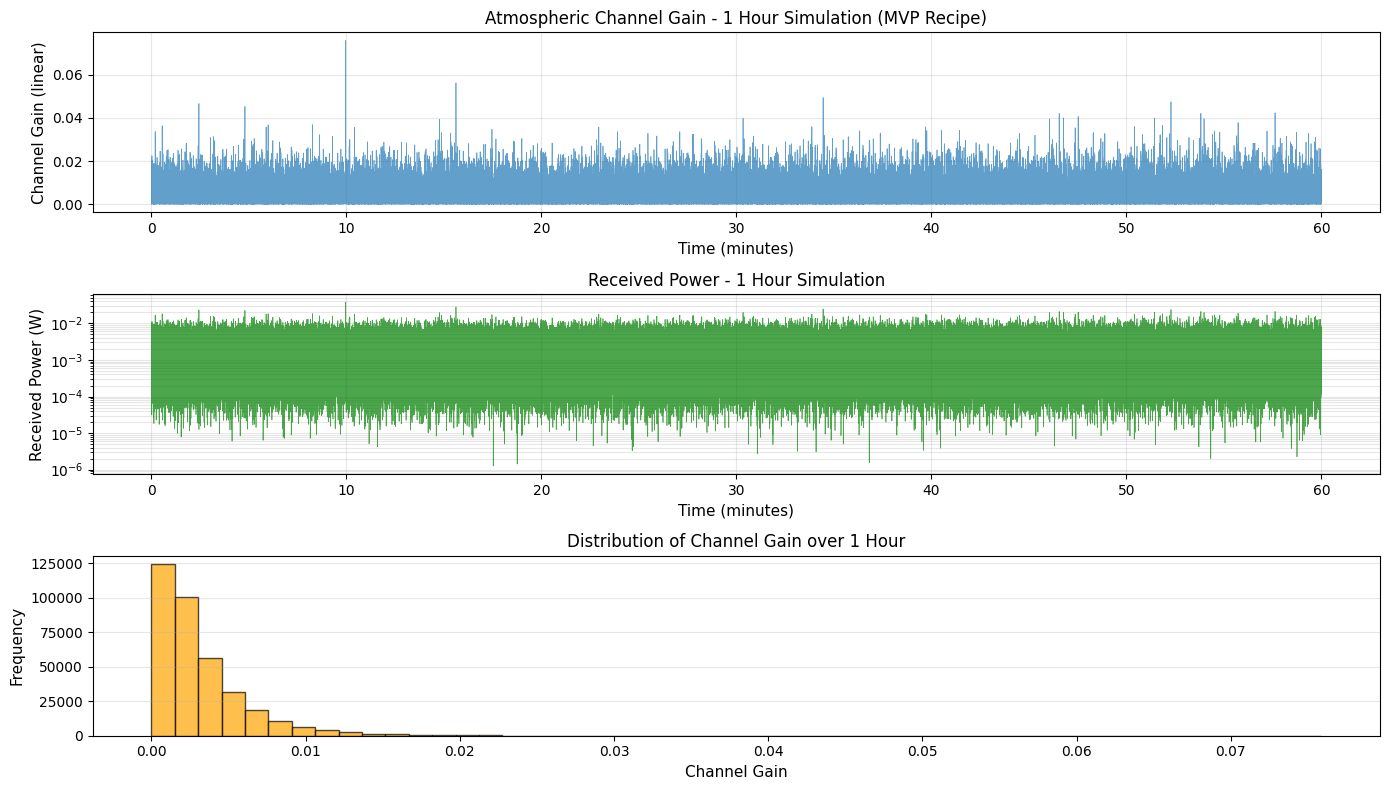


=== 1-Hour Simulation Statistics ===
Gain - Mean: 3.1816e-03, Std: 3.0789e-03
Gain - Min: 2.5387e-06, Max: 7.5885e-02
Power (W) - Mean: 1.5908e-03, Std: 1.5394e-03
Power (W) - Min: 1.2694e-06, Max: 3.7943e-02
Outage Probability (P < 1e-06 W): 0.0000 (0/360000 samples)


In [21]:
## Time-Series Simulation: 1 Hour Channel Dynamics

# Create atmospheric channel
ch_atm = Channel.environment("atmospheric").defaults("mvp").build(
    distance_m=1000,
    wavelength_nm=1550,
    pt_w=0.5,
    visibility_km=2.0,
    theta_rad=1e-3,
    DT_m=0.05,
    DR_m=0.1,
    gg_alpha=3.2,
    gg_beta=2.1,
    jitter_sigma_m=0.01,
    wz_eq_m=0.08
)

# Define simulation parameters for 1 hour
duration_hours = 1
sampling_rate_hz = 100  # samples per second (adjust as needed)
total_samples = int(duration_hours * 3600 * sampling_rate_hz)  # 1 hour in samples

print(f"Simulating {duration_hours} hour(s) at {sampling_rate_hz} Hz")
print(f"Total samples: {total_samples:,}")

# Generate channel gain samples over 1 hour
gain_samples = ch_atm.sample(total_samples)

# Create time array (in seconds)
time_seconds = np.arange(total_samples) / sampling_rate_hz
time_minutes = time_seconds / 60.0

# Calculate received power from gain
received_power_samples = ch_atm.link.tx.power_dbm  # Get transmit power in dBm
pt_watts = 10**(received_power_samples / 10.0) * 1e-3  # Convert to Watts
pr_watts = pt_watts * gain_samples

# Plot results
plt.figure(figsize=(14, 8))

# Plot 1: Channel Gain over time
plt.subplot(3, 1, 1)
plt.plot(time_minutes, gain_samples, linewidth=0.5, alpha=0.7)
plt.xlabel('Time (minutes)', fontsize=11)
plt.ylabel('Channel Gain (linear)', fontsize=11)
plt.title('Atmospheric Channel Gain - 1 Hour Simulation (MVP Recipe)', fontsize=12)
plt.grid(True, alpha=0.3)

# Plot 2: Received Power over time (log scale)
plt.subplot(3, 1, 2)
plt.semilogy(time_minutes, pr_watts, linewidth=0.5, alpha=0.7, color='green')
plt.xlabel('Time (minutes)', fontsize=11)
plt.ylabel('Received Power (W)', fontsize=11)
plt.title('Received Power - 1 Hour Simulation', fontsize=12)
plt.grid(True, which='both', alpha=0.3)

# Plot 3: Statistics (histogram of gain)
plt.subplot(3, 1, 3)
plt.hist(gain_samples, bins=50, edgecolor='black', alpha=0.7, color='orange')
plt.xlabel('Channel Gain', fontsize=11)
plt.ylabel('Frequency', fontsize=11)
plt.title('Distribution of Channel Gain over 1 Hour', fontsize=12)
plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Print statistics
print(f"\n=== 1-Hour Simulation Statistics ===")
print(f"Gain - Mean: {np.mean(gain_samples):.4e}, Std: {np.std(gain_samples):.4e}")
print(f"Gain - Min: {np.min(gain_samples):.4e}, Max: {np.max(gain_samples):.4e}")
print(f"Power (W) - Mean: {np.mean(pr_watts):.4e}, Std: {np.std(pr_watts):.4e}")
print(f"Power (W) - Min: {np.min(pr_watts):.4e}, Max: {np.max(pr_watts):.4e}")

# Outage analysis (power below 1 µW)
outage_threshold = 1e-6  # 1 microwattz
outage_count = np.sum(pr_watts < outage_threshold)
outage_probability = outage_count / total_samples
print(f"Outage Probability (P < {outage_threshold:.0e} W): {outage_probability:.4f} ({outage_count}/{total_samples} samples)")

## 3. Manual Composition: Deep Space Example

This shows how to instantiate a specific model class manually. This is useful when you want total control.

In [5]:
from owcm.space.models.deepspace import DeepSpaceTableXIII

# Configure a Deep Space Link (Long distance)
tx_space = Tx(power_dbm=40.0, wavelength_nm=1550.0) # 10W laser
rx_space = Rx(aperture_diameter_m=0.5)
rx_space.position = np.array([0, 0, 1e9]) # 1 million km

link_space = Link(tx=tx_space, rx=rx_space)
env_space = Environment(name="Deep Space")

# Instantiate the model directly
# It requires specific parameters like w0_rad
model = DeepSpaceTableXIII(link_space, env_space, w0_rad=10e-6, sigma_p=1e-6)

gain = model.gain(link_space, env_space)
print(f"Channel Gain: {gain:.4e}")
print(f"Received Power: {model.gain(link_space, env_space) * 10.0:.4e} Watts")

Channel Gain: 6.3281e-09
Received Power: 6.3281e-08 Watts


## 4. "Cooking" New Models (Custom Models)

You can easily add your own models. The library is plug-and-play.

### Steps:
1.  **Define** a class matching the `ChannelModel` protocol (must have `gain`, `sample`, `describe`).
2.  **Decorate** it with `@register_model(env, category, name)`.
3.  **Use** it immediately via the registry or direct import.

In [6]:
from owcm.core.registry import register_model

# Let's create a custom atmospheric model that just assumes 3dB loss per km
@register_model("atmospheric", "loss", "simple_3db")
class Simple3dBModel:
    def __init__(self, link, env, **kwargs):
        self.loss_per_km = 3.0 # dB

    def gain(self, link, env, rng=None):
        dist_km = link.range_m / 1000.0
        total_db_loss = self.loss_per_km * dist_km
        linear_loss = 10 ** (-total_db_loss / 10.0)
        return linear_loss

    def sample(self, link, env, n, rng=None):
        return np.full(n, self.gain(link, env))

    def describe(self):
        return {"name": "Simple 3dB/km Loss"}

# Verify it's registered
print("Atmospheric Models:", registry.list_models("atmospheric")["loss"])

# Usage
env_custom = Environment(name="Custom Atm")
my_model = Simple3dBModel(link, env_custom)
# Link defined in previous cells
print(f"Gain for 1km link: {my_model.gain(link, env_custom):.4f}")

Atmospheric Models: ['simple_3db']
Gain for 1km link: 0.5012


## 5. Defaults & Recipes (High-Level API)

Most of the time, you don't want to manually assemble `Tx`, `Rx`, `Link` and instantiate individual model classes. 
You want to say: *"Give me a standard Deep Space channel, but change the pointing jitter."*

This is done via the **Environment Builder** API: `Channel.environment(...)`.

In [7]:
from owcm.channel import Channel

# 1. Start with an environment
builder = Channel.environment("space")

# 2. Load a default recipe
# This automatically picks a set of models for loss, pointing, turbulence, etc.
builder.defaults("deep_space")

# 3. Build the channel, passing parameters
# Params are passed to ALL sub-models. They pick what they need.
# We can also configure the Link/Tx/Rx here directly.
channel = builder.build(
    distance_m=1e9, 
    pt_w=10.0,              # 10 Watts
    wavelength_nm=1550, 
    DT_m=0.5,               # Tx Aperture
    DR_m=0.5,               # Rx Aperture
    w0_rad=10e-6,           # DeepSpace model param
    sigma_p=1e-6            # DeepSpace model param
)

print("Constructed Channel Description:")
print(channel.describe())

print(f"\nReceived Power: {channel.received_power():.4e} W")

Constructed Channel Description:
{'environment': 'space', 'link': {'range_m': np.float64(1000000000.0), 'wavelength_nm': 1550}, 'model': {'type': 'CompositeChannel', 'components': [{'name': 'FreeSpacePathLoss'}, {'name': 'DiffLimitedTx'}, {'name': 'TelescopeRx'}, {'name': 'None'}, {'name': 'None'}, {'name': 'LinkBudgetChain'}]}}


TypeError: DiffLimitedTx.gain() got an unexpected keyword argument 'rng'

### Overriding Models in a Recipe

What if you want to use the standard 'deep_space' recipe, but want to turn off pointing errors? 
You don't need a new recipe. You can just swap that component.

In [8]:
# Use method chaining
channel_no_pointing = Channel.environment("space") \
    .defaults("deep_space") \
    .model("pointing", "none") \
    .build(
        distance_m=1e9, 
        pt_w=10.0, 
        w0_rad=10e-6
        # sigma_p is irrelevant now because the pointing model is 'none'
    )

print(f"Power without pointing errors: {channel_no_pointing.received_power():.4e} W")


TypeError: DiffLimitedTx.gain() got an unexpected keyword argument 'rng'

### Creating Your Own Recipes

You can define your own standard configurations (Recipes). This is effectively just a dictionary mapping categories to model names.

In [9]:
from owcm.core.defaults import register_recipe

# Define a custom recipe for Atmospheric channel
# using our 'simple_3db' model created earlier
register_recipe("atmospheric", "my_rainy_day", {
    "loss": "simple_3db",  # The custom model
    "turbulence": "none",  # No turbulence
    "pointing": "none"     # No pointing errors
})

# Now you can use it just like a built-in one
my_channel = Channel.environment("atmospheric") \
    .defaults("my_rainy_day") \
    .build(
        distance_m=5000, # 5 km
        wavelength_nm=1550
    )

# Should reflect 3dB/km * 5km = 15dB loss = 10^-1.5 = 0.0316
print(f"Gain (5km, 3dB/km): {my_channel.gain():.4f}")

ValueError: Model 'none' (category 'turbulence') not found in registry for environment 'atmospheric'.

## 6. Advanced: Multiplying with an Existing Model (Chaining)

Sometimes you want to take a standard recipe (like Deep Space) and just multiply it by your own custom factor (e.g., a specific optical filter loss or a safety margin) without altering the recipe or registering a new model.

Because `CompositeChannel` is itself a model, you can nest them! You can bundle an existing complicated model with your simple factor.

In [ ]:
from owcm.core.composite import CompositeChannel
from owcm.core.types import ChannelModel

# 1. Build the standard channel (Deep Space)
base_channel = Channel.environment("space").defaults("deep_space").build(
    distance_m=1e9, pt_w=10.0, w0_rad=10e-6, sigma_p=1e-6
)

# 2. Define your extra gain factor
class SafetyMargin:
    def gain(self, link, env, rng=None):
        return 0.8 # 20% loss (Side factor)
    
    def sample(self, link, env, n, rng=None):
        return np.full(n, 0.8)
        
    def describe(self):
        return {"name": "Safety Margin (0.8)"}

# 3. Combine them
# We create a NEW composite that contains the [Base Model, Safety Margin]
# The Base Model (which is already a composite) acts as one block.
final_model = CompositeChannel([base_channel.model, SafetyMargin()])

# 4. Calculate
# You can call gain() directly on this new combined model
base_gain = base_channel.gain()
total_gain = final_model.gain(base_channel.link, base_channel.env)

print(f"Base Gain:  {base_gain:.4e}")
print(f"Final Gain: {total_gain:.4e} (should be 0.8 * Base)")
print(f"Check:      {total_gain / base_gain:.2f}")